<img src='http://drive.google.com/uc?export=view&id=1ZhMMgLVVc2Tm79BanxAusgHB51pgC6iL'>

# <font color='lightblue'>Making Predictions</font>

In this project you will build a model to make predictions. This project will build on your exploritory data analyitic (EDA) skills. You may choose to use the datasets you used with project 1 or move to another dataset.

In this project you will:

1.  Develop an understanding of the dataset
2.  Do exploritory data analysis and visualzation
3.  Do some data preprocessing
4.  Build a predictive model
5.  Measure the performance of your model
6.  Summarize and interpret your results



### This project was completed by:


*   Ahmed Muhammad
*   Joy Umejiego
*   Sandra Igboanugo

We are continuing with the UCI heart disease dataset from Project 1. In Project 1 we cleaned the data and used a Spearman heatmap to see which clinical markers move with heart disease. In this project we take it a step further and ask: **can we predict whether a patient has heart disease from their clinical markers?**

We use a decision tree classifier for this. It's one of the models we covered in class, and it lets us draw the model and see exactly which markers it uses to make a decision.

**Action:** Import python libraries


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.inspection import permutation_importance

## <font color='lightblue'>1. Data Understanding </font>

**Action:** Import your data into colaboratory.


In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download("redwankarimsony/heart-disease-data")

csv_path = os.path.join(path, "heart_disease_uci.csv")
health_data_df = pd.read_csv(csv_path)

print(health_data_df.shape)
health_data_df.head(4)

Using Colab cache for faster access to the 'heart-disease-data' dataset.
(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0


The dataset has 920 patients and 16 columns.

**Action:** Determine the types of data are you dealing with & handle missing data (if there is any!). *Marks (0.5)*

In [ ]:
print("Data Types:\n", health_data_df.dtypes)
print("\nMissing Values per column:\n", health_data_df.isna().sum())

Data Types:
 id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object

Missing Values per column:
 id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


**Continuous numeric:** age (years), trestbps (resting blood pressure, mm Hg), chol (serum cholesterol, mg/dl), thalch (max heart rate achieved, bpm), oldpeak (ST depression induced by exercise)

**Discrete / ordinal numeric:** ca (number of major vessels coloured by fluoroscopy, 0-3, stored as float only because of the missing values), num (disease severity, 0 = none, 1-4 = increasing severity)

**Binary categorical:** sex (Male / Female), fbs (fasting blood sugar > 120 mg/dl, True / False), exang (exercise-induced angina, True / False)

**Nominal categorical:** cp (chest pain type), restecg (resting ECG result), thal (thallium test result), dataset (the hospital the patient came from, renamed to origin below)

**Ordinal categorical:** slope (slope of the peak exercise ST segment)

**id** is just a patient number, so it won't be used as a predictor.

sex, fbs, exang, cp and restecg are stored as text or True/False (object), and scikit-learn can't use them like that. We fix this in the preprocessing section.

In [ ]:
# Impossible values are set to NaN, since nobody can have 0 cholesterol or 0 blood pressure
health_data_df.loc[health_data_df['chol'] == 0, 'chol'] = np.nan #
health_data_df.loc[health_data_df['trestbps'] == 0, 'trestbps'] = np.nan
health_data_df.rename(columns={'dataset': 'origin'}, inplace=True)

# % of missing values in each column
(health_data_df.isna().mean() * 100).round(1).sort_values(ascending=False)

,0
ca,66.4
thal,52.8
slope,33.6
chol,22.0
fbs,9.8
oldpeak,6.7
trestbps,6.5
thalch,6.0
exang,6.0
restecg,0.2


Several columns have a lot of missing values: ca (66%), thal (53%), slope (34%) and chol (22%, mostly the 172 zeros we just turned into NaN). This isn't random. Some hospitals just didn't record certain tests, for example ca was only properly recorded in Cleveland and cholesterol was never recorded in Switzerland.

There are three ways we could deal with this: fill in the gaps with the median, fill them in with 0, or drop the rows. Before choosing, we checked whether the patients with missing values are different from the patients without them.

In [ ]:
health_data_df['diseased'] = (health_data_df['num'] != 0).astype(int) # 0 (false)= no disease, 1-4 (true) = disease

A decision tree looks for any value that separates diseased from healthy patients. If we filled every missing cholesterol with the median (about 240), there would suddenly be over 200 patients sitting at exactly 240, most of them diseased, and the tree could learn "cholesterol = 240 means diseased". Filling with 0 has the same problem, the tree could learn "ca = 0 or chol = 0 means a certain outcome", just based on which patients happened to have missing values. The original dataset actually shows this already: the 172 zero cholesterol values were placeholders for missing readings, and those patients were mostly diseased. Either way, the tree would be learning which hospital didn't record a test, not anything about the patient's heart.

So we drop the rows with missing values instead. We keep ca, since it had the strongest correlation with disease severity in Project 1 (r = 0.53) and we want to see how much it helps the model. We drop thal and slope as columns, since we decided to focus our analysis on ca and keeping them would only add more missing values to deal with (thus reducing the dataset for training further!).

In [ ]:
# drop thal and slope, then drop any rows with missing values
health_clean_df = health_data_df.drop(['thal', 'slope'], axis=1)
health_clean_df = health_clean_df.dropna(how='any')

# ca is a count of vessels, now that there are no NaNs it can be stored as a whole number
health_clean_df['ca'] = health_clean_df['ca'].astype(int)

print(health_clean_df.shape)
print(health_clean_df.isna().sum().sum(), "missing values left")
health_clean_df['origin'].value_counts()


(302, 15)
0 missing values left


,count
origin,
Cleveland,299
Hungary,2
VA Long Beach,1


In [ ]:
health_clean_df['diseased'].value_counts(normalize=True)*100

,proportion
diseased,
0,53.642384
1,46.357616


We're left with 302 patients and no missing values. Keeping ca has a big effect on who is left: 299 of the 302 patients are from Cleveland, since that's the only hospital that properly recorded ca. This means our model is really a Cleveland model, and we need to keep that in mind when we talk about how well it generalizes. On the other hand, the remaining patients are a fair mix of diseased and healthy (approx 46% diseased), so dropping the missing rows didn't leave us with only sick or only healthy patients.

**Action:** Estimate the summary statistics of some of the key variables. *Marks (0.5)*

In [ ]:
key_vars = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

summary = health_clean_df[key_vars].describe().round(2)

print(summary)

          age  trestbps    chol  thalch  oldpeak
count  302.00    302.00  302.00  302.00   302.00
mean    54.49    131.65  246.28  149.27     1.05
std      8.99     17.67   52.55   23.10     1.16
min     29.00     94.00  100.00   71.00     0.00
25%     48.00    120.00  211.00  132.25     0.00
50%     56.00    130.00  240.50  152.50     0.80
75%     61.00    140.00  275.00  165.00     1.60
max     77.00    200.00  564.00  202.00     6.20


In [ ]:
# average of each key variable (and ca) for patients without (0) and with (1) heart disease
health_clean_df.groupby('diseased')[key_vars + ['ca']].mean().round(2)

,age,trestbps,chol,thalch,oldpeak,ca
diseased,,,,,,
0,52.63,129.11,242.86,158.32,0.59,0.27
1,56.65,134.59,250.24,138.80,1.58,1.12


In [ ]:
# This is just to have a look at the data we have in each of the columns we want to use in the decision tree
print(health_clean_df['diseased'].value_counts(), "\n")
print(health_clean_df['sex'].value_counts(), "\n")
print(health_clean_df['cp'].value_counts(), "\n")
print(health_clean_df['ca'].value_counts().sort_index())

diseased
0    162
1    140
Name: count, dtype: int64 

sex
Male      205
Female     97
Name: count, dtype: int64 

cp
asymptomatic       145
non-anginal         84
atypical angina     50
typical angina      23
Name: count, dtype: int64 

trestbps
94.0      2
100.0     4
101.0     1
102.0     2
104.0     1
105.0     3
106.0     1
108.0     6
110.0    19
112.0     9
114.0     1
115.0     3
117.0     1
118.0     7
120.0    39
122.0     4
123.0     1
124.0     6
125.0    10
126.0     3
128.0    12
129.0     1
130.0    36
132.0     7
134.0     5
135.0     6
136.0     3
138.0    10
140.0    32
142.0     3
144.0     2
145.0     5
146.0     2
148.0     2
150.0    18
152.0     5
154.0     1
155.0     1
156.0     1
158.0     1
160.0    11
164.0     1
165.0     1
170.0     4
172.0     1
174.0     1
178.0     2
180.0     3
192.0     1
200.0     1
Name: count, dtype: int64
thalch
71.0     1
88.0     1
90.0     1
95.0     1
96.0     2
        ..
190.0    1
192.0    1
194.0    1
195.0    1
202.0    1

The average patient is about 56 years old, with a resting blood pressure of 134.6 mm Hg and cholesterol of 250.24 mg/dl. At least a quarter of patients show no ST depression at all (oldpeak 25th percentile = 0).

Splitting by disease status shows where the differences are. Diseased patients are about 4 years older, reach a lower max heart rate (139 vs 158 bpm), have nearly three times the ST depression (1.58 vs 0.59) and have on average about one blocked vessel (ca 1.12 vs 0.27). Their cholesterol and resting blood pressure are only a little higher, which matches what we found in Project 1 (the correlation heatmap).

is mostly male (205 vs 97), asymptomatic is the most common chest pain type (145 patients), and most patients have no blocked vessels (179 with ca = 0).

## <font color='lightblue'>2. Data Exploration and Visualization </font>

**Action:** Visualize 1- the distribution of values for some key variables, and 2- the relationships between key variables. Remember to add text that walks a reader through what you found. *Marks: 2*

### Distributions

/tmp/ipykernel_2083/2942772112.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['No disease (0)', 'Disease (1)'])


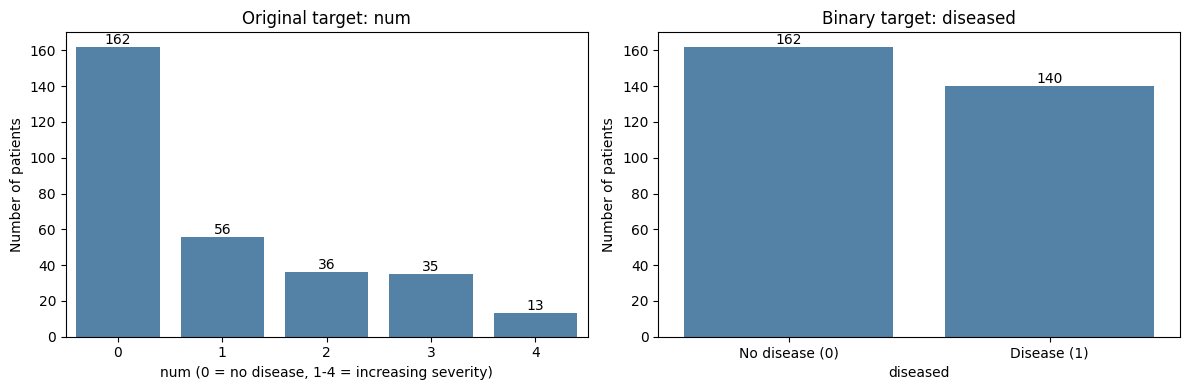

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=health_clean_df, x='num', color='steelblue', ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_xlabel('num (0 = no disease, 1-4 = increasing severity)')
axes[0].set_ylabel('Number of patients')
axes[0].set_title('Original target: num')

sns.countplot(data=health_clean_df, x='diseased', color='steelblue', ax=axes[1])
axes[1].bar_label(axes[1].containers[0])
axes[1].set_xticklabels(['No disease (0)', 'Disease (1)'])
axes[1].set_xlabel('diseased')
axes[1].set_ylabel('Number of patients')
axes[1].set_title('Binary target: diseased')

plt.tight_layout()
plt.show()

num is very uneven. 162 patients have no disease, but severities 2 and 3 have only 36 and 35 patients and severity 4 has just 13. If we kept num as five classes, the model would have very few examples of the higher severity levels to learn from. Collapsing it into diseased (0/1) gives two groups of similar size. We test this choice properly in section 4.

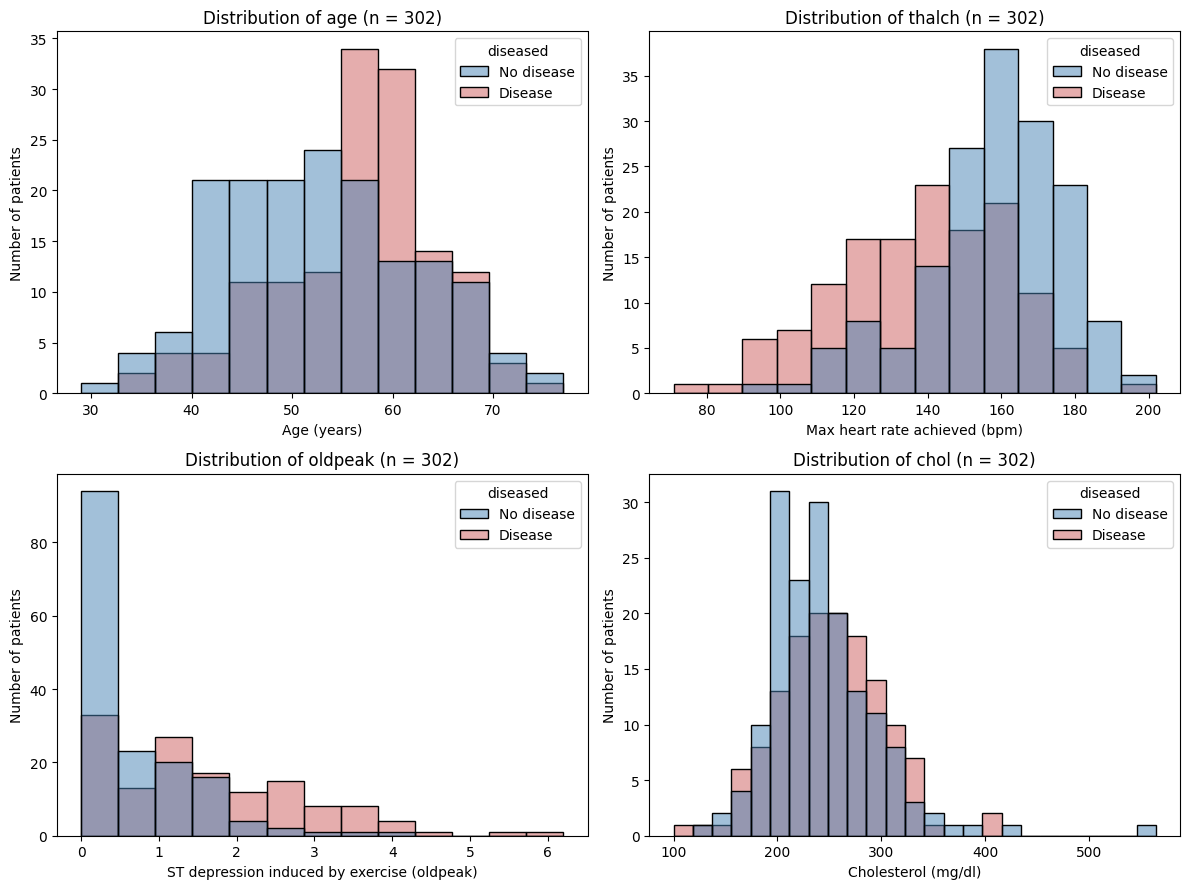

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

hist_vars = {'age': 'Age (years)',
             'thalch': 'Max heart rate achieved (bpm)',
             'oldpeak': 'ST depression induced by exercise (oldpeak)',
             'chol': 'Cholesterol (mg/dl)'}
# The following code was picked from online, and to understand:
# zip -> combines axes.flatten and hist_vars.items
# Now hist_vars.items is a dictionary. axes.flatten() turns the axes [0,0],axes[0,1] into a long form
# For each plot, take the next variable from hist_vars, and give me the plot as ax, the column name as col, and its friendly label as label.
for ax, (col, label) in zip(axes.flatten(), hist_vars.items()):
    sns.histplot(data=health_clean_df, x=col, hue='diseased', palette=['steelblue', 'indianred'], alpha=0.5, ax=ax) #alpha=0.5 controls transparency!
    ax.set_xlabel(label)
    ax.set_ylabel('Number of patients')
    ax.set_title(f'Distribution of {col} (n = {len(health_clean_df)})')
    #For text, set new_label. zip() Basically pairs values
    #ax.get_legend().text -> basically means get the current labels as texts
    #which are "0" and "1" and replace them as No disease and Diseased
    for text, new_label in zip(ax.get_legend().texts, ['No disease', 'Disease']):
        #This just sets the label as the new labels
        text.set_text(new_label)

plt.tight_layout()
plt.show()

Each histogram is split by disease status so we can see both the overall shape and how the two groups differ.

**age** is roughly bell-shaped around the mid-50s. The diseased group (red) sits further right, peaking in the late 50s and early 60s, while the healthy group is spread across the 40s and early 50s.

**thalch** is slightly left-skewed. This is where the separation is clearest: healthy patients cluster around 150-180 bpm, while diseased patients are spread lower, mostly 100-160 bpm.

**oldpeak** is heavily right-skewed with a big spike at 0. Most of that spike is healthy patients (72 healthy vs 26 diseased at exactly 0), while most of the values above 1.5 belong to diseased patients.

**chol** is right-skewed with a few extreme values, the highest at 564. The two groups overlap almost completely, so cholesterol on its own doesn't tell us much about who is diseased.

### Relationships between variables

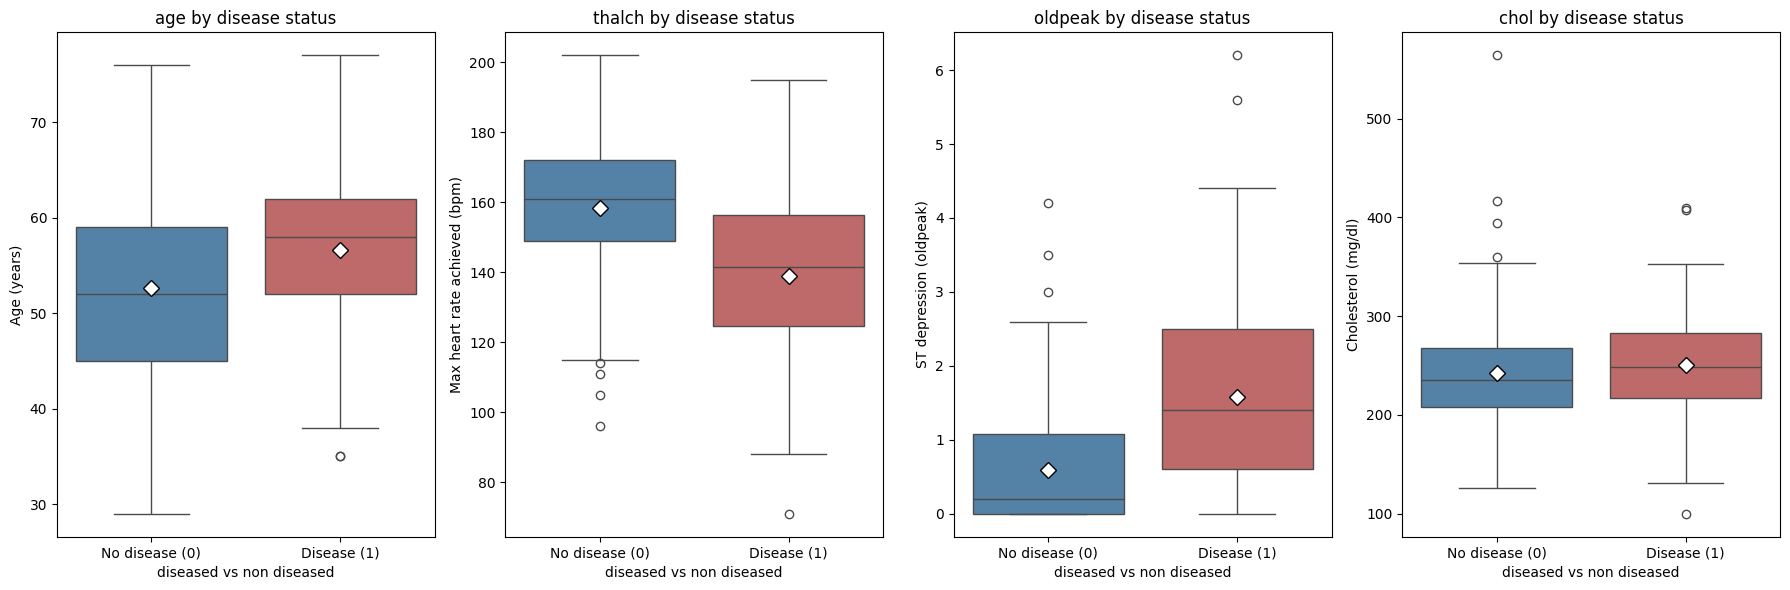

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6))

box_vars = {'age': 'Age (years)',
            'thalch': 'Max heart rate achieved (bpm)',
            'oldpeak': 'ST depression (oldpeak)',
            'chol': 'Cholesterol (mg/dl)'}

for ax, (col, label) in zip(axes, box_vars.items()):
    sns.boxplot(data=health_clean_df, x='diseased', y=col, hue='diseased', legend=False,
                palette=['steelblue', 'indianred'], ax=ax, showmeans=True,
                meanprops={"marker":"D", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"8"})
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No disease (0)', 'Disease (1)'])
    ax.set_xlabel('diseased vs non diseased')
    ax.set_ylabel(label)
    ax.set_title(f'{col} by disease status')

plt.tight_layout()
plt.show()

The boxplots back up the histograms. For **age** we can see that the mean age for the diseased group is slightly higher (by apporximately 5 years). However, this can also be caused by the data collected - younger people with heart diseased may not come in for check up more often, so not really deterministic here. For **thalch** the whole box shifts down for diseased patients (median 142 vs 161 bpm), so diseased hearts can't be pushed as hard during exercise. For **oldpeak** the healthy group's box sits between 0 and about 1.1, while the diseased group's box runs from about 0.6 to 2.5 with a median of 1.4, so more ST depression goes with disease. For **chol** the two boxes are nearly on top of each other, the same weak link we saw in Project 1.

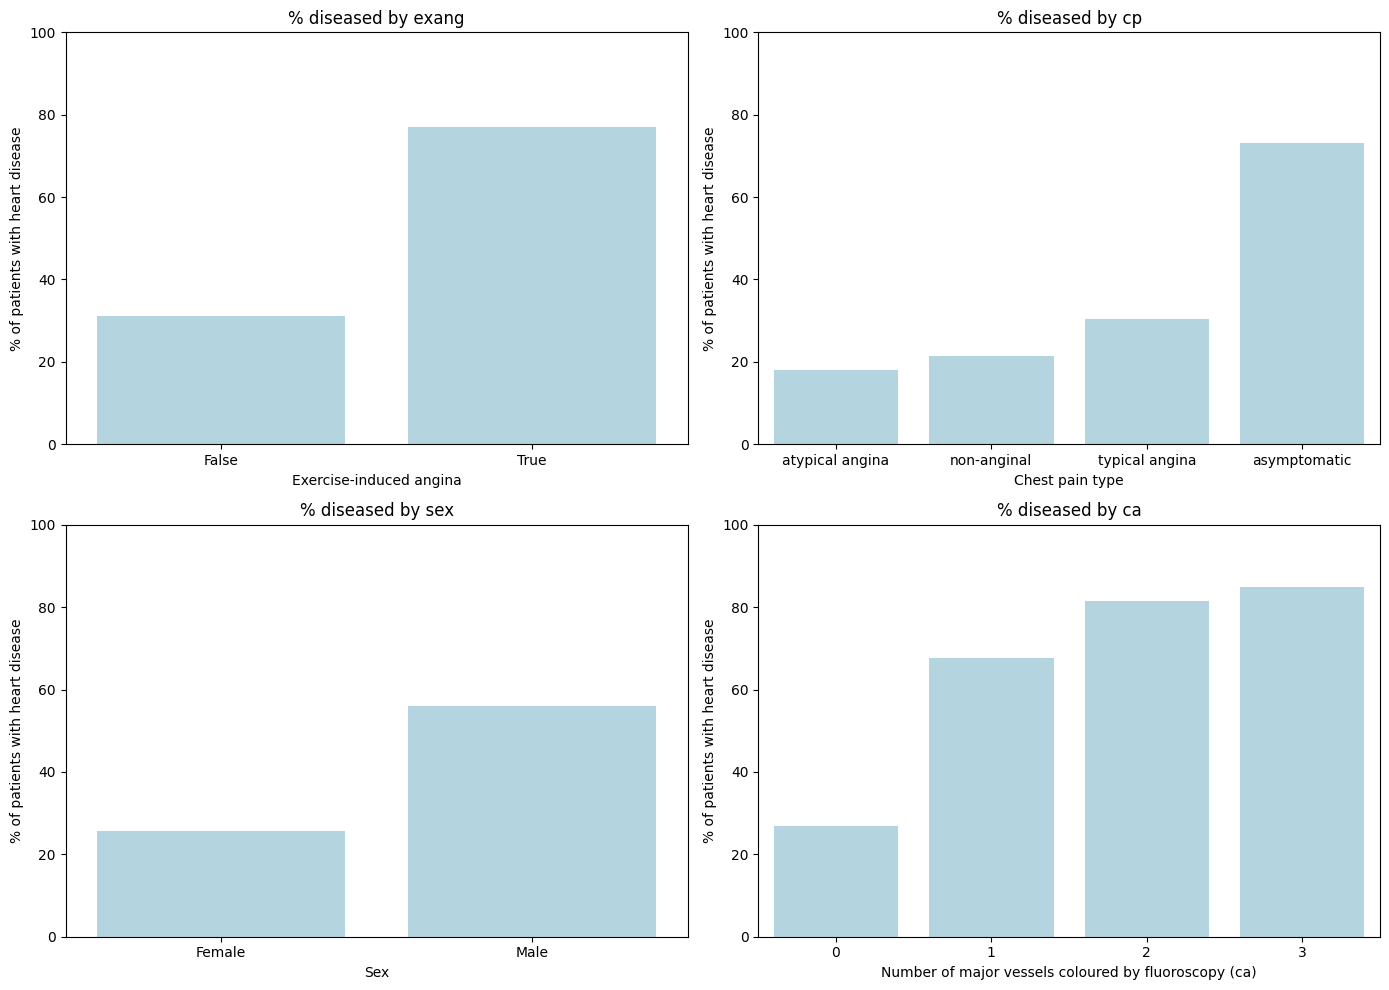

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cat_vars = {'exang': 'Exercise-induced angina',
            'cp': 'Chest pain type',
            'sex': 'Sex',
            'ca': 'Number of major vessels coloured by fluoroscopy (ca)'}

for ax, (col, label) in zip(axes.flatten(), cat_vars.items()):
  #Here we are just dividing the given column by the diseased status, and then finding the mean of diseased vs no diseaesed
    disease_rate = (health_clean_df.groupby(col)['diseased'].mean() * 100).sort_values()
    sns.barplot(x=disease_rate.index.astype(str), y=disease_rate.values, color='lightblue', ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel('% of patients with heart disease')
    ax.set_ylim(0, 100)
    ax.set_title(f'% diseased by {col}')

plt.tight_layout()
plt.show()

For the categorical variables we plotted the % of patients in each group who have heart disease.

**exang:** 77% of patients who get chest pain during exercise are diseased, compared to 31% of those who don't.

**cp:** this one surprised us. Patients with **asymptomatic** chest pain are the most likely to be diseased (73%), while atypical angina (18%) and non-anginal pain (21%) are the least. You would expect the opposite, but these are patients who were referred for heart testing. Someone sent for testing without the usual chest pain was probably sent because of other warning signs.

**sex:** 56% of men are diseased vs 26% of women. Since the sample is about two-thirds male, the model will see more male examples.

**ca:** the clearest step pattern of all. Only 27% of patients with no blocked vessels are diseased, and this rises to 68% with one, 82% with two and 85% with three. More vessels showing blockage means a much higher chance of heart disease.

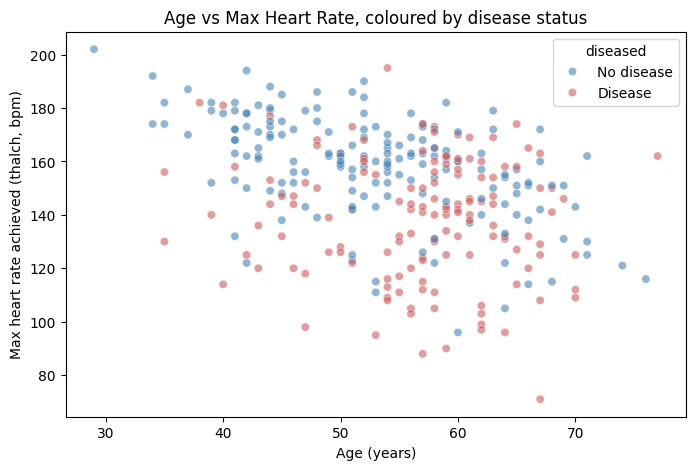

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.scatterplot(data=health_clean_df, x='age', y='thalch', hue='diseased',
                     palette=['steelblue', 'indianred'], alpha=0.6)

for text, new_label in zip(ax.get_legend().texts, ['No disease', 'Disease']):
    text.set_text(new_label)

plt.title('Age vs Max Heart Rate, coloured by disease status')
plt.xlabel('Age (years)')
plt.ylabel('Max heart rate achieved (thalch, bpm)')
plt.show()

Putting two variables together, max heart rate drops as age goes up, and the diseased patients (red) mostly sit in the lower part of the plot, especially on the right: older and with a lower max heart rate. Healthy patients fill the top left. There's still a lot of overlap in the middle, so no single pair of variables cleanly separates the two groups. This is a good sign that a model combining several variables could do better than any one on its own.

**Action:** Use correlation to estimate the relationship between some of the key variables. Remember to add text that helps a reader interpret the correlations. *Marks: 1*

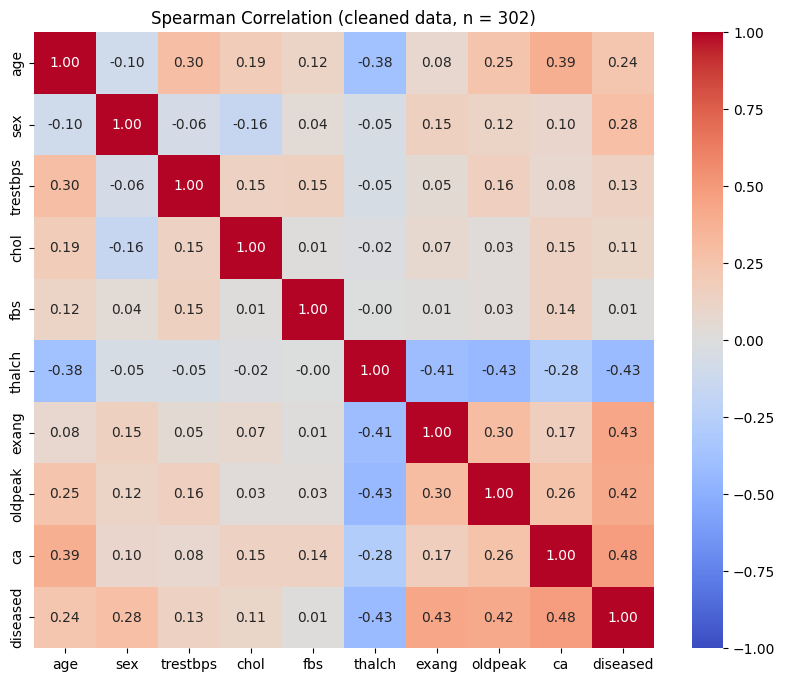

In [ ]:
corr_vars = ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak', 'ca', 'diseased']

# sex, fbs and exang converted to 1/0 just for the correlation
corr_matrix = (
    health_clean_df[corr_vars]
    .assign(sex=(health_clean_df['sex'] == 'Male').astype(int),
            fbs=(health_clean_df['fbs'] == True).astype(int),
            exang=(health_clean_df['exang'] == True).astype(int))
    .corr(method='spearman')
)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Spearman Correlation (cleaned data, n = 302)")
plt.show()


We used Spearman because ca is an ordinal count, and sex, fbs and exang are binary, so a rank-based correlation is safer than Pearson. This time we correlate with **diseased** (0/1) instead of num.

**ca and diseased (r ≈ 0.48):** the strongest relationship, moderate and positive. The more major vessels showing blockage, the more likely the patient has heart disease.

**exang and diseased (r ≈ 0.43):** moderate positive. Patients who get chest pain during exercise are more likely to have heart disease.

**thalch and diseased (r ≈ -0.43):** moderate negative. Diseased patients can't push their heart rate as high, the same pattern we found with num in Project 1.

**oldpeak and diseased (r ≈ 0.42):** moderate positive. More ST depression during exercise goes with disease.

**sex (0.28) and age (0.24):** weak positive. Men and older patients are somewhat more likely to be diseased.

**trestbps (0.13), chol (0.11) and fbs (0.01):** weak to none. These barely move with disease.

One thing to keep in mind for the model: exang, oldpeak and thalch are also correlated with each other (thalch and oldpeak r ≈ -0.43, thalch and exang r ≈ -0.41, exang and oldpeak r ≈ 0.30). All three come from the same exercise stress test, so they partly carry the same information, and the model may not need all of them. cp isn't in the heatmap because it's a nominal variable with four categories (multi categorical), but the bar chart above already shows it has a strong link with disease.

## <font color='lightblue'>3. Data preprocessing </font>

**Action:** Do you need to apply any preprocessing steps? E.g., convert a binary variable to 1/0, or use one-hot encoding to convert categorical variables? Apply at least one preprocessing step, and explain why you used it. *Marks: 2*

We apply three preprocessing steps.

**1. Binary variables to 1/0.** sex, fbs and exang are stored as text or True/False. scikit-learn only works with numbers, so we convert them: Male = 1 and Female = 0, True = 1 and False = 0.

**2. One-hot encoding for cp and restecg.** These are nominal categories with no natural order. If we just numbered chest pain types 0, 1, 2, 3, the model would treat "asymptomatic" as bigger than "typical angina", which doesn't mean anything. One-hot encoding gives each category its own 0/1 column instead, so each one is treated separately.

**3. num to a binary target (diseased).** We already created diseased (0 = no disease, 1 = any severity) in section 1, and this is what we predict instead of the 0-4 scale. Severity 3 and 4 only have 35 and 13 patients, too few for the tree to learn them, and the question we care about is whether a patient has heart disease, not how severe it is. We check this decision with an actual model in section 4.

In [ ]:
health_model_df = health_clean_df.copy()

# Step 1: binary variables to 1/0
health_model_df['sex'] = (health_model_df['sex'] == 'Male').astype(int)   # Male = 1, Female = 0
health_model_df['fbs'] = (health_model_df['fbs'] == True).astype(int)     # True = 1, False = 0
health_model_df['exang'] = (health_model_df['exang'] == True).astype(int) # True = 1, False = 0

# Step 2: one-hot encode cp and restecg
category_cols = ['cp', 'restecg']
df_cat = pd.get_dummies(health_model_df[category_cols], dtype=int)

health_model_df = pd.concat([health_model_df, df_cat], axis=1)
health_model_df.drop(category_cols, axis=1, inplace=True)

health_model_df.head()

,id,age,sex,origin,trestbps,chol,fbs,thalch,exang,oldpeak,ca,num,diseased,cp_asymptomatic,cp_atypical angina,cp_non-anginal,cp_typical angina,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality
0,1,63,1,Cleveland,145.0,233.0,1,150.0,0,2.3,0,0,0,0,0,0,1,1,0,0
1,2,67,1,Cleveland,160.0,286.0,0,108.0,1,1.5,3,2,1,1,0,0,0,1,0,0
2,3,67,1,Cleveland,120.0,229.0,0,129.0,1,2.6,2,1,1,1,0,0,0,1,0,0
3,4,37,1,Cleveland,130.0,250.0,0,187.0,0,3.5,0,0,0,0,0,1,0,0,1,0
4,5,41,0,Cleveland,130.0,204.0,0,172.0,0,1.4,0,0,0,0,1,0,0,1,0,0


Every column is now numeric. cp became four columns (cp_asymptomatic, cp_atypical angina, cp_non-anginal, cp_typical angina) and restecg became three. Each patient has a 1 in exactly one cp column and one restecg column.

**Action:** Split your data into training and testing datasets *Marks: 1*

First we pick our predictors (X) and target (y). We leave out **id** (just a patient number), **num** (the original target, it would give the answer away) and **origin**. Almost every patient is from Cleveland now, so origin carries no useful information, and we wouldn't want the model to learn "which hospital did they go to" instead of "what is going on with their heart" anyway.

In [ ]:
X = health_model_df.drop(['id', 'origin', 'num', 'diseased'], axis=1)
y = health_model_df['diseased']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print("Predictors:", list(X.columns), "\n")
print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)
print(f"% diseased in training: {y_train.mean()*100:.1f}%") #.1f means 1 decimal place, floating value!
print(f"% diseased in testing:  {y_test.mean()*100:.1f}%")

Predictors: ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak', 'ca', 'cp_asymptomatic', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina', 'restecg_lv hypertrophy', 'restecg_normal', 'restecg_st-t abnormality'] 

Training set: (241, 16)
Testing set:  (61, 16)
% diseased in training: 46.5%
% diseased in testing:  45.9%


We used an 80/20 split, as in class, which gives 241 patients for training and 61 for testing. The split is random, and random_state=42 makes sure we get the same split every time we run the notebook. stratify=y keeps the share of diseased patients the same in both sets (46.5% and 45.9%), so the test set isn't accidentally easier or harder than the training set. The test set is only used to check how well the model does on patients it hasn't seen.

**Action: (optional)** Scale any numeric variables. If you have no binary or categorical variables that need transforming, scaling will count towards your marks for your preprocessing step.

We didn't scale our numeric variables. A decision tree works by asking yes/no questions like "is oldpeak > 0.7?". Scaling changes the numbers but not the order of the patients, so the tree would end up making exactly the same splits. Leaving the variables unscaled also keeps the tree easy to read, because the thresholds stay in real units (bpm, mm Hg, years, number of vessels) instead of z-scores.

## <font color='lightblue'>4. Build a model</font>



**Action:** Use your training dataset to build a model with the goal of predicting a target variable. *Marks: 2*

Our target is **diseased** (1 = heart disease, 0 = none), so this is a classification problem. We used a **decision tree classifier** like in class. A decision tree is a set of yes/no questions that keeps splitting patients into smaller groups, and each final group (a leaf) predicts whichever class most of its patients belong to. We chose it because we can draw the whole model and follow how it reaches a decision, which matters when the predictions are about heart disease.

First we fit a tree with the default settings, like we did with the wine dataset in class.

In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("Training accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Tree depth:", model.get_depth())
print("Number of leaves:", model.get_n_leaves())

Training accuracy: 1.0
Tree depth: 8
Number of leaves: 39


The default tree gets 100% on the training data. That sounds great, but it's a warning sign. The tree kept asking questions until it was 8 levels deep with 39 leaves, and many of those leaves hold only one or two patients. In other words it has memorized the 241 training patients, noise included, instead of learning general patterns. A tree like that usually does worse on new patients.

The fix is to limit how many levels of questions the tree is allowed to ask, using max_depth. To see which depth works, we fit trees from depth 1 to 10 and compare their accuracy on the training and testing data.

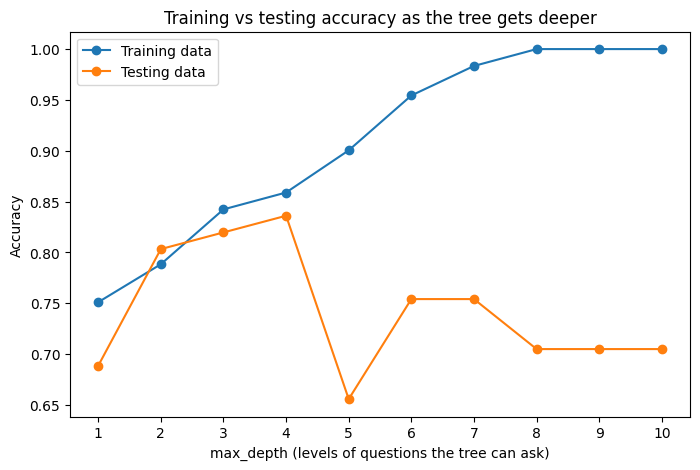

,max_depth,train_accuracy,test_accuracy
0,1,0.751,0.689
1,2,0.788,0.803
2,3,0.842,0.820
3,4,0.859,0.836
4,5,0.900,0.656
5,6,0.954,0.754
6,7,0.983,0.754
7,8,1.000,0.705
8,9,1.000,0.705
9,10,1.000,0.705


In [ ]:
depth_results = []

for depth in range(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    depth_results.append({'max_depth': depth,
                          'train_accuracy': accuracy_score(y_train, tree.predict(X_train)),
                          'test_accuracy': accuracy_score(y_test, tree.predict(X_test))})

depth_df = pd.DataFrame(depth_results)

plt.figure(figsize=(8, 5))
plt.plot(depth_df['max_depth'], depth_df['train_accuracy'], marker='o', label='Training data')
plt.plot(depth_df['max_depth'], depth_df['test_accuracy'], marker='o', label='Testing data')
plt.xlabel('max_depth (levels of questions the tree can ask)')
plt.ylabel('Accuracy')
plt.title('Training vs testing accuracy as the tree gets deeper')
plt.xticks(range(1, 11))
plt.legend()
plt.show()

depth_df.round(3)

This plot shows overfitting clearly. Training accuracy keeps climbing as the tree gets deeper and hits 100% from depth 8 onwards, because a deeper tree can memorize more patients. Testing accuracy goes the other way after a point. It peaks at depth 3 and 4 (82% and 84%), then drops, falling as low as 66% at depth 5 and settling around 70%. The extra questions the deeper trees ask only fit the training patients, they don't help with new ones.

We picked max_depth = 3. Depth 4 is slightly higher on the testing data, but depth 3 tree is easier to read. Strictly speaking, choosing the depth by looking at the test set is a small cheat, since the test set is meant to be unseen.

We also checked our choice of target by fitting the same depth 3 tree on num (5 classes) instead of diseased:

In [ ]:
y_num_train = health_model_df.loc[X_train.index, 'num']
y_num_test = health_model_df.loc[X_test.index, 'num']

num_model = DecisionTreeClassifier(max_depth=3, random_state=42)
num_model.fit(X_train, y_num_train)

print(f"num (0-4) test accuracy: {accuracy_score(y_num_test, num_model.predict(X_test)):.3f}")

num (0-4) test accuracy: 0.541


With five classes the tree gets 54% right, exactly the same as calling everyone "no disease", so it learned nothing useful about severity. With the binary target it gets 82%. So collapsing num into diseased was the right call for this dataset.

Now the final model:

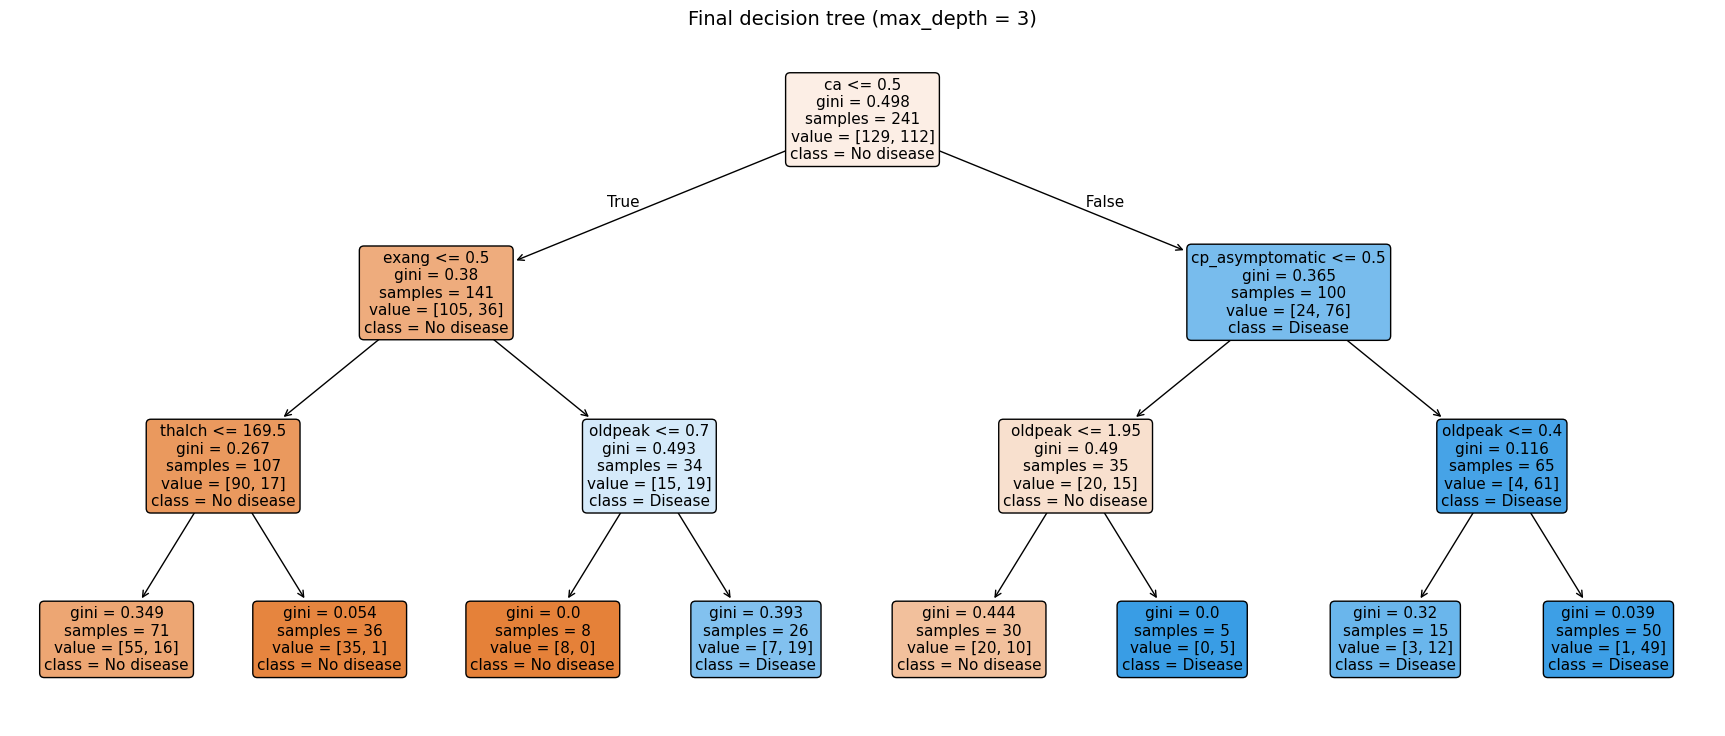

In [ ]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

plt.figure(figsize=(22, 9))
plot_tree(tree_model, feature_names=list(X.columns), class_names=['No disease', 'Disease'],
          filled=True, rounded=True, fontsize=11)
plt.title('Final decision tree (max_depth = 3)', fontsize=14)
plt.show()

Each box shows the question, the number of training patients that reach it (samples), how many are healthy vs diseased (value), and the predicted class. Orange boxes lean "no disease" and blue boxes lean "disease". True always goes to the left.

The first question the tree asks is about **ca**: does the patient have any blocked vessels? Of the 141 training patients with no blocked vessels (left side), only 26% are diseased. For them the tree next asks about **exang**. Without exercise-induced angina, almost everyone is predicted healthy (17 of 107 diseased). With exercise-induced angina, the tree checks oldpeak, and those with oldpeak above 0.7 are predicted diseased (19 of 26). The thalch split at the bottom left doesn't change the prediction, both sides are predicted healthy, it just separates a very healthy group (1 of 36 diseased above 169.5 bpm) from a less certain one.

Of the 100 patients with at least one blocked vessel (right side), 76% are diseased. If their chest pain is also **asymptomatic**, the tree predicts disease no matter what (61 of 65 diseased). If not, it only predicts disease when oldpeak is above 1.95.

A few leaves are very small (5, 8 and 15 patients). Those splits are based on so few people that we wouldn't trust them much on their own.

## <font color='lightblue'>5. Measure performance</font>

**Action:** Use your testing dataset to estimate the performance of your model. Add text describing what kind of measure you used. *Marks: 2*

We tested the final tree on the 61 patients it has never seen, using four measures.

**Accuracy** is the share of all patients classified correctly. **Precision** is, out of the patients the model flags as diseased, how many actually are. **Recall** (sensitivity) is, out of the patients who actually have heart disease, how many the model catches. For a medical problem recall is the one we care about most, because a missed diseased patient (a false negative) could be sent home without treatment. The **confusion matrix** shows the counts behind these numbers.

We also compared against a baseline of always predicting the most common class ("no disease") to see whether the model is actually adding anything.

In [ ]:
y_pred = tree_model.predict(X_test)

model_acc = accuracy_score(y_test, y_pred)
model_prec = precision_score(y_test, y_pred)
model_rec = recall_score(y_test, y_pred)
baseline_acc = y_test.value_counts(normalize=True).max()

print(f"baseline accuracy (always 'no disease'): {baseline_acc:.2f}")
print(f"accuracy:  {model_acc:.2f}")
print(f"precision: {model_prec:.2f}")
print(f"recall:    {model_rec:.2f}")

baseline accuracy (always 'no disease'): 0.54
accuracy:  0.82
precision: 0.95
recall:    0.64


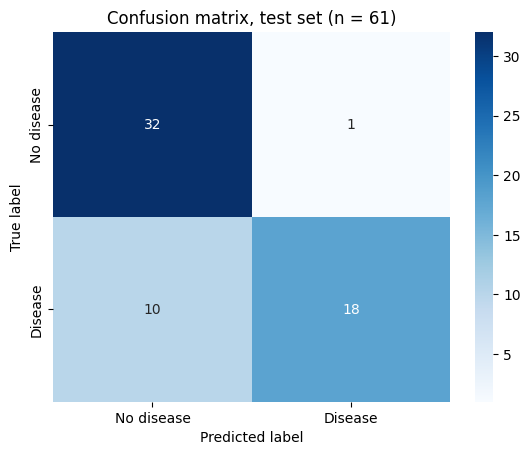

In [ ]:
cm_tree = confusion_matrix(y_test, y_pred)

sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No disease', 'Disease'], yticklabels=['No disease', 'Disease'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion matrix, test set (n = 61)')
plt.show()

The tree gets 82% of test patients right, compared to 54% for the baseline, so it's clearly learning something real. Precision is very high (0.95): when the model says "disease" it's almost always right, only 1 healthy patient was wrongly flagged. Recall is the weak spot (0.64). The model catches 18 of the 28 diseased patients in the test set and misses 10. In other words this tree is cautious, it only says "disease" when it's sure. For a medical problem that's the wrong way round, since missing a diseased patient is worse than sending a healthy one for more tests. As it stands, this tree would only be useful as one input alongside other tests, not as a screen on its own.

Next, we compared training and testing accuracy for the default tree and our final tree:

In [ ]:
compare_df = pd.DataFrame({
    'model': ['Default tree (no depth limit)', 'Final tree (max_depth = 3)'],
    'train_accuracy': [accuracy_score(y_train, model.predict(X_train)), accuracy_score(y_train, tree_model.predict(X_train))],
    'test_accuracy': [accuracy_score(y_test, model.predict(X_test)), model_acc]
})

compare_df.round(3)

,model,train_accuracy,test_accuracy
0,Default tree (no depth limit),1.000,0.705
1,Final tree (max_depth = 3),0.842,0.820


The default tree drops from 100% on training data to 70% on new patients, a 30 point gap, which is classic overfitting. Our final tree scores 84% on training and 82% on testing, a gap of only 2 points. The simpler tree turns out to be the better model.

Finally, since keeping ca cost us most of the dataset, we checked how much it actually helps. We fit the same depth 3 tree on the same patients, just without the ca column:

In [ ]:
no_ca_model = DecisionTreeClassifier(max_depth=3, random_state=42)
no_ca_model.fit(X_train.drop('ca', axis=1), y_train)

print(f"test accuracy with ca:    {model_acc:.3f}")
print(f"test accuracy without ca: {accuracy_score(y_test, no_ca_model.predict(X_test.drop('ca', axis=1))):.3f}")

test accuracy with ca:    0.820
test accuracy without ca: 0.770


Removing ca drops test accuracy from 82% to 77%, about 3 patients out of 61. So ca does add something on top of the stress test variables. With a test set this small we wouldn't read too much into the exact gap, but it fits with ca being the strongest correlate and the first split in the tree.

## <font color='lightblue'>6. Discussion and interpretation</font>

To answer the questions below we first looked at which variables the model relies on, using permutation importance like in class.

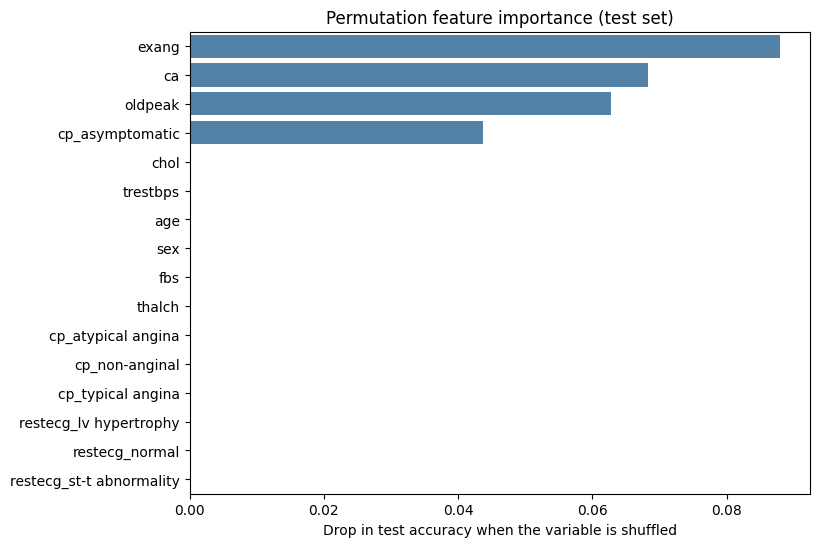

,feature,importance,sd
6,exang,0.088,0.032
8,ca,0.068,0.031
7,oldpeak,0.063,0.032
9,cp_asymptomatic,0.044,0.024
3,chol,0.000,0.000
2,trestbps,0.000,0.000
0,age,0.000,0.000
1,sex,0.000,0.000
4,fbs,0.000,0.000
5,thalch,0.000,0.000


In [ ]:
rel_impo = permutation_importance(tree_model, X_test, y_test, n_repeats=30, random_state=42)

df_feature_importance = pd.DataFrame({'feature': X_test.columns,
                                      'importance': rel_impo.importances_mean,
                                      'sd': rel_impo.importances_std})
df_feature_importance.sort_values(by='importance', ascending=False, inplace=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=df_feature_importance, y='feature', x='importance', color='steelblue')
plt.xlabel('Drop in test accuracy when the variable is shuffled')
plt.ylabel('')
plt.title('Permutation feature importance (test set)')
plt.show()

df_feature_importance.round(3)

Permutation importance shuffles one column at a time on the test set and measures how much accuracy drops. A big drop means the model really depends on that variable. Shuffling exang costs 9 percentage points of accuracy, ca 7 points, oldpeak 6 points and cp_asymptomatic 4 points. Everything else has zero importance, either because the tree never uses it (age, sex, chol, trestbps, fbs, restecg) or because its split doesn't change the prediction (thalch). The sd column shows these estimates are fairly noisy, again because the test set only has 61 patients.

Importance tells us how much a variable matters, but not which direction it pushes the prediction. For that we go back to the tree diagram, where each split shows how many healthy and diseased patients end up on each side.

**Q1:**
> What have you learnt about the ability to model and predict your variable of interest? *Marks: 1*

> What variables are responsible for the predictive ability of your model, and what does your model suggest about the relationships these variables have with your target variable? (i.e., think magnitude and sign of each effect). *Marks: 2*

> How did these relationships generalize to the with-held sample (i.e., testing data sample)? *Marks: 1*

**Answer: Ability to model and predict heart disease**

Whether a patient has heart disease turned out to be fairly predictable from a handful of clinical measurements. Our final tree classifies 82% of unseen patients correctly, compared to 54% if we just guessed "no disease" for everyone. The model only needs a few questions to get there: number of blocked vessels, exercise-induced angina, ST depression and chest pain type. Making the tree deeper made it worse, not better.

The model does have clear limits. Its recall is only 0.64, so it misses about 1 in 3 diseased patients, which is too many to use it for diagnosis or even screening on its own. Predicting severity (num 0-4) didn't work at all, the tree did no better than guessing "no disease" for everyone, mostly because so few patients are at the higher severity levels. Keeping ca also meant keeping only patients who had it recorded, which left us with 302 patients, almost all from Cleveland. With a test set of only 61 patients, every result here could shift by a few points with a different split, and we can't assume the model would work the same way at other hospitals or in the general population.

**Answer: Variables behind the predictions (magnitude and sign)**

All the numbers below come from the training patients in the tree diagram.

**ca** is the first question the tree asks and has the second highest permutation importance (7 points). Only 26% of patients with no blocked vessels are diseased (36 of 141), compared to 76% of patients with at least one (76 of 100). This is a strong positive effect: more blocked vessels means a much higher chance of disease, which matches the step pattern in the section 2 bar chart (27% at 0 vessels up to 85% at 3).

**exang** has the highest permutation importance (9 points). Among patients with no blocked vessels, only 16% of those without exercise-induced angina are diseased (17 of 107), compared to 56% of those with it (19 of 34). So it's a positive effect, and it matters most for patients whose vessels look clear.

**oldpeak** shows up in three places in the tree, always with the same sign: more ST depression pushes the prediction towards disease. For example, among patients with clear vessels and exercise-induced angina, 73% of those with oldpeak above 0.7 are diseased (19 of 26), compared to none of the 8 with oldpeak at or below 0.7. Shuffling it costs 6 points of accuracy.

**cp_asymptomatic** is a positive effect for patients with blocked vessels. 94% of patients with blocked vessels and asymptomatic chest pain are diseased (61 of 65), compared to 43% of those with other chest pain types (15 of 35). This seems backwards at first, but as we said in section 2, patients sent for heart testing without the usual chest pain were probably sent because of other warning signs.

**thalch** points in the negative direction, since patients with a max heart rate above 169.5 bpm are almost all healthy (1 of 36 diseased). But both sides of that split are predicted healthy anyway, so it doesn't change any predictions and its importance is zero.

**age**, **sex**, **chol**, **trestbps**, **fbs** and **restecg** weren't used by the tree at all. For chol, trestbps and fbs this fits their weak correlations. Age and sex had weak positive correlations, but once the tree knows about blocked vessels and the stress test results, they add too little to earn a split in a tree this small.

These are patterns the model uses to predict, not causes. Like the UC Berkeley admissions example from class, which variables a model leans on depends on what else is included, so we can't say any of these variables cause heart disease.

**Answer: Generalizing to the test data**

The relationships held up reasonably well on the 61 with-held patients. The final tree scored 84% on the training data and 82% on the testing data, a gap of only 2 points. The permutation importance was calculated on the test set, and it agrees with the structure the tree learned from the training set: exang, ca, oldpeak and cp_asymptomatic are the variables that matter on unseen patients too.

The default tree shows what happens without the depth limit. It was 100% accurate on the training data but fell to 70% on the test set because it had memorized individual patients rather than general patterns. The depth plot in section 4 shows the same thing step by step: past depth 4, training accuracy keeps rising while testing accuracy drops. Limiting the depth to 3 gave up some training accuracy, but the model generalizes much better.

There are a few things to be careful about. The test set is small (61 patients), so each patient is worth about 1.6 percentage points, and the 82% could easily move by several points with a different split. We also used the test set to help pick the depth, so the 82% may be slightly optimistic. And nearly all of our patients, training and testing, are from Cleveland, so this shows the model generalizes to other Cleveland patients, not necessarily to other hospitals.